## IMF Kroupa (2001)

La IMF es una power law por intervalos, $\xi(m) = k_i\, m^{-\alpha_i}$:

| Rango [$M_{\odot}$] | $\alpha$ |
|---|---|
|0.01 - 0.08 | 0.3 |
|0.08 - 0.5  | 1.3 |
|0.5 - 100   | 2.3 |

Las constantes $k_i$ surgen cuando se impone continuidad en cada quiebre, tal que:
$k_i = k_{i-1}\, m_i^{\alpha_i - \alpha_{i-1}}$, con $k_0 = 1$.

Se adopta $M_{\max} = 100\,M_\odot$. Los objetos con $M < 0.08\,M_\odot$ son enanas marrones y se clasifican aparte.

In [1]:
from scipy.optimize import brentq
import numpy as np
import matplotlib.pyplot as plt
from astroquery.vizier import Vizier
from scipy.stats import ks_2samp

In [2]:
seed = 42
rng = np.random.default_rng(seed)

mass_ranges = np.array([0.01, 0.08, 0.5, 100])
alphas = np.array([0.3, 1.3, 2.3])

In [3]:
k = np.ones(len(alphas))
for i in range(1, len(alphas)):
    k[i] = k[i-1] * mass_ranges[i]**(alphas[i] - alphas[i-1])

print(k)

[1.   0.08 0.04]


In [4]:
def kroupa_imf(m):
    """
    IMF de Kroupa sin normalizar, continua en los quiebres.
    Entrada: m, masa(s) en Msun (escalar o array)
    Salida:  xi(m); vale 0 fuera de [mass_ranges[0], mass_ranges[-1]]
    """
    m = np.asarray(m, dtype=float)
    xi = np.zeros_like(m)
    for i in range(len(alphas)):
        rango = (m >= mass_ranges[i]) & (m < mass_ranges[i + 1])
        xi[rango] = k[i] * m[rango]**(-alphas[i])
    xi[m == mass_ranges[-1]] = k[-1] * mass_ranges[-1]**(-alphas[-1])   # incluir m_max
    return xi

Para obtener el número de estrellas en un intervalo de masas debemos integrar:

$$ N_{i} = \int_{m_i}^{m_{i+1}} k_i\, m^{-\alpha_i}\,dm $$

Resolvemos la integral y definimos $p_i$ como:

$$ \int m^{-\alpha_i}\, dm = \frac{m^{1-\alpha_i}}{1-\alpha_{i}}, \qquad p_i = 1- \alpha_i $$

Podemos reescribir la integral como:

$$ N_{i} = k_{i}\, \frac{m_{i+1}^{p_i} - m_i^{p_i}}{p_i} = w_i $$

Por lo tanto, $w_i$ representa la integral de la IMF en cada uno de sus tramos.
La suma de las contribuciones de los tramos no da 1, por lo que es necesario normalizar. La constante $a$ se define como:

$$ a = \frac{1}{\sum w_i} $$

De esta forma, $p(m) = a\,\xi(m)$ integra a 1.

La probabilidad de caer en un intervalo es el área bajo la densidad en ese intervalo, por lo que:

$$ P_i = a\, w_i = \frac{w_i}{\sum w_i} $$

La función de distribución acumulada se define como:

$$ F(m) = P(M \leq m) = \int_{m_{\min}}^{m} p(m')\, dm' $$

En los quiebres, $F(m_j) = \sum_{i<j} P_i$.

In [5]:
# Normalización de la IMF por tramos

p = 1 - alphas                                            # exponente de la integral
w = k * (mass_ranges[1:]**p - mass_ranges[:-1]**p) / p    # integral de la IMF en cada tramo
a = 1 / w.sum()                                           # constante de normalización
f_breaks = np.concatenate(([0], np.cumsum(w) * a))        # CDF en cada quiebre

print("P por tramos:", w * a)
print("F en quiebres:", f_breaks)

P por tramos: [0.37148817 0.47811341 0.15039842]
F en quiebres: [0.         0.37148817 0.84960158 1.        ]


### Generador de masas

Los números aleatorios se generan con `np.random.default_rng(seed)`, con `seed = 42`.

`u` son números aleatorios uniformes entre 0 y 1. Con ellos aplicamos el método de la transformada inversa:

$$ m = F^{-1}(u) $$

Primero se determina a qué tramo pertenece cada $u$ usando `searchsorted` y la CDF en los quiebres:

F en quiebres: [0, 0.371, 0.850, 1]

Por ejemplo, $u = 0.15$ pertenece al primer tramo y $u = 0.5$ al segundo. Dentro del tramo $i$ se despeja:

$$ M = \left[ m_i^{p_i} + \frac{p_i\,(u - F(m_i))}{a\,k_i} \right]^{1/p_i} $$

In [6]:
def sample_kroupa(n, rng):
    """
    Genera masas iniciales siguiendo la IMF de Kroupa (transformada inversa por tramos).
    Entradas: n, número de estrellas; rng, np.random.Generator
    Salida:   array (n,) de masas en Msun
    """
    u = rng.uniform(size=n)
    i = np.searchsorted(f_breaks, u, side='right') - 1    # tramo de cada u
    pi = p[i]
    return (mass_ranges[i]**pi + pi * (u - f_breaks[i]) / (a * k[i]))**(1 / pi)

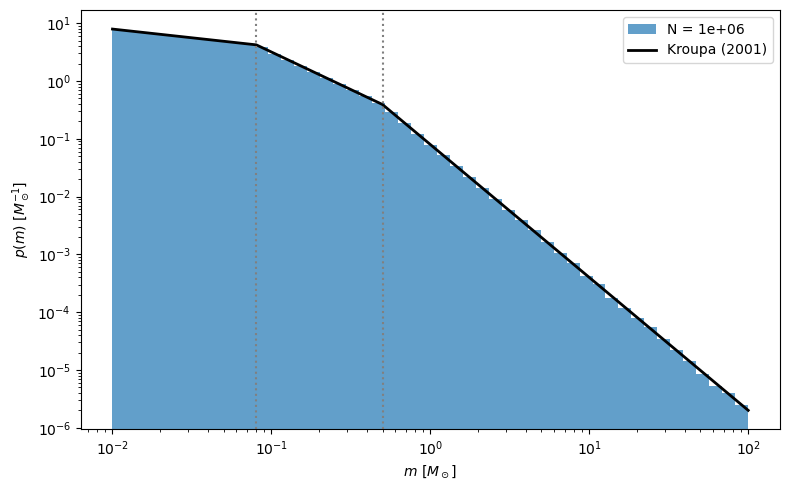

In [7]:
N = 10**6
M = sample_kroupa(N, rng)

bins = np.logspace(np.log10(mass_ranges[0]), np.log10(mass_ranges[-1]), 50)

plt.figure(figsize=(8, 5))
plt.hist(M, bins=bins, density=True, alpha=0.7, label=f'N = {N:.0e}' )
m_plot = np.logspace(np.log10(mass_ranges[0]), np.log10(mass_ranges[-1]), 1000)
plt.plot(m_plot, a * kroupa_imf(m_plot), 'k-', lw=2, label='Kroupa (2001)')

for mb in mass_ranges[1:-1]:
    plt.axvline(mb, ls=':', c='gray')

plt.xscale('log')
plt.yscale('log')

plt.xlabel(r"$m\ [M_\odot]$")
plt.ylabel(r"$p(m)\ [M_\odot^{-1}]$")

plt.legend()
plt.tight_layout()
plt.savefig("figs/IMF-Kroupa")
plt.show()

In [8]:
# Validación numérica con la misma muestra M del gráfico (no se vuelve a sortear)
print("Masa mínima:", M.min())
print("Masa máxima:", M.max())
print("Número de objetos:", len(M))

print("\nTramo            Teoría    Muestra")
for i in range(len(alphas)):
    lo, hi = mass_ranges[i], mass_ranges[i + 1]
    frac = np.mean((M >= lo) & (M < hi))
    print(f"{lo:5.2f} – {hi:6.2f}   {w[i]*a:.4f}    {frac:.4f}")

Masa mínima: 0.010000015801212911
Masa máxima: 99.85859125980448
Número de objetos: 1000000

Tramo            Teoría    Muestra
 0.01 –   0.08   0.3715    0.3712
 0.08 –   0.50   0.4781    0.4784
 0.50 – 100.00   0.1504    0.1503


## Parte I.b: Historia de formación estelar y tiempo de vida en MS

- SFR constante: $t_{\rm birth} \sim U(0, T_{MW})$, con $T_{MW} = 10$ Gyr
- Edad actual: $t_{\rm age} = T_{MW} - t_{\rm birth}$
- Tiempo de vida en MS: $t_{MS} = 10\ {\rm Gyr}\,(M/M_\odot)^{-2.5}$
- Si $t_{\rm age} < t_{MS}$ la estrella sigue en MS; si no, evolucionó.
- Los objetos con $M < 0.08\,M_\odot$ son enanas marrones (BD) y se clasifican aparte.

In [9]:
T_MW = 10.0        # Gyr, edad de la galaxia
T_MS_SUN = 10.0    # Gyr, tiempo de vida en MS de una estrella de 1 Msun
MS_EXP = -2.5      # t_MS ∝ M^-2.5
M_H_BURN = 0.08    # Msun, bajo esto no hay fusión de H (enana marrón)

Z_sun = 0.014      # Metalicidad Sol
MU_F = 0.10        # Initial Gas fraction
y_eff = Z_sun / np.log(1 / MU_F) #Effective yield
MH_FLOOR = -3.0

In [10]:
def sample_birth_times(n, rng):
    """Tiempos de nacimiento [Gyr] con SFR constante: t_birth ~ U(0, T_MW)."""
    return rng.uniform(0.0, T_MW, size=n)

def ms_lifetime(M):
    """Tiempo de vida en secuencia principal [Gyr] para masa(s) M [Msun]."""
    return T_MS_SUN * M**MS_EXP

In [11]:
birth_times = sample_birth_times(N, rng) 
print(f"media: {birth_times.mean():.4f}   (teoría: {T_MW/2:.4f})")
print(f"std:   {birth_times.std():.4f}   (teoría: {T_MW/np.sqrt(12):.4f})")

media: 4.9982   (teoría: 5.0000)
std:   2.8858   (teoría: 2.8868)


### Clasificación: MS o evolucionada

Cada estrella tiene una masa M y un tiempo desde que nació (birthtime)
Si $t_{\rm age} > t_{MS}$, la estrella ya salió de la secuencia principal.

In [12]:
t_age = T_MW - birth_times
t_MS = ms_lifetime(M)

is_BD = M < M_H_BURN                           # Brown Dwarfs
is_evolved = (M >= M_H_BURN) & (t_age > t_MS)  # Evolved stars
is_MS = (M >= M_H_BURN) & (t_age <= t_MS)      # MS stars

n_stars = np.sum(M >= M_H_BURN)

print(f"Enanas marrones: {is_BD.mean():.4f} del total")
print(f"MS:              {is_MS.sum()/n_stars:.4f} de las estrellas")
print(f"Evolucionadas:   {is_evolved.sum()/n_stars:.4f} de las estrellas")
print(f"Masa mínima evolucionada: {M[is_evolved].min():.3f} Msun")

Enanas marrones: 0.3712 del total
MS:              0.9361 de las estrellas
Evolucionadas:   0.0639 de las estrellas
Masa mínima evolucionada: 1.002 Msun


In [13]:
if is_evolved.sum() > 0:
    M_evolved = M[is_evolved]
    M_WD = M_evolved[M_evolved < 8.0]
    M_NS = M_evolved[(M_evolved >= 8.0) & (M_evolved < 20.0)]
    M_BH = M_evolved[M_evolved >= 20.0]

    print(f"Estrellas evolucionadas: {is_evolved.sum()} de {n_stars} estrellas")
    print(f" - Enanas blancas (M < 8 Msun): {len(M_WD)}")
    print(f" - Estrellas de neutrones (8 <= M < 20 Msun): {len(M_NS)}")
    print(f" - Agujeros negros (M >= 20 Msun): {len(M_BH)}")

Estrellas evolucionadas: 40204 de 628762 estrellas
 - Enanas blancas (M < 8 Msun): 36288
 - Estrellas de neutrones (8 <= M < 20 Msun): 2812
 - Agujeros negros (M >= 20 Msun): 1104


In [14]:
def gas_fraction(t):

    """Calcula la fracción de gas del modelo

    Parámetros
    ----------
    
    
    
    
    
    """

    t = np.asarray(t, dtype=float)
    return 1.0 - (1.0 - MU_F) * t / T_MW

def closed_box(t):

    """Calcula la evolución química bajo el modelo de caja cerrada (Closed Box Model).

    Parámetros
    ----------
    gas_mass : float
        Masa de gas inicial o actual del sistema.
    star_mass : float
        Masa acumulada en estrellas.
    yield_factor : float
        Rendimiento químico neto (true yield).

    Retorna
    -------
    float
        Metalicidad esperada según el modelo.
    """

    return y_eff * np.log(1.0 / gas_fraction(t))

def Z_to_MH(Z):

    """Convierte la fracción de masa de metales (Z) a metalicidad [M/H] relativa al Sol.

    Parámetros
    ----------
    Z : float o array_like
        Fracción en masa de metales de la estrella o gas.
    Z_solar : float, opcional
        Metalicidad del Sol como referencia (por defecto 0.0134, Asplund et al. 2009).

    Retorna
    -------
    float o ndarray
        Valor de metalicidad [M/H] en escala logarítmica.
    """

    Z = np.asarray(Z, dtype=float)
    with np.errstate(divide="ignore"):
        MH = np.log10(Z / Z_sun)
    return np.maximum(MH, MH_FLOOR)

In [15]:
# --- Metalicidad de nacimiento de cada estrella ---
Z_birth = closed_box(birth_times)   # se evalúa en t_birth, NO en t_age
MH = Z_to_MH(Z_birth)

# Chequeo rápido contra la predicción analítica (población completa)
MH_cut = -0.5
Z_cut = Z_sun * 10**MH_cut
frac_teo = (1 - np.exp(-Z_cut / y_eff)) / (1 - MU_F)
frac_sim = np.mean(MH < MH_cut)

print(f"[M/H] rango: {MH.min():.2f} a {MH.max():.3f}")
print(f"Fracción en el piso (MH = {MH_FLOOR}): {np.mean(MH == MH_FLOOR):.4f}")
print(f"Fracción con [M/H] < {MH_cut}: simulada {frac_sim:.4f}  |  analítica {frac_teo:.4f}")

[M/H] rango: -3.00 a -0.000
Fracción en el piso (MH = -3.0): 0.0025
Fracción con [M/H] < -0.5: simulada 0.5751  |  analítica 0.5747


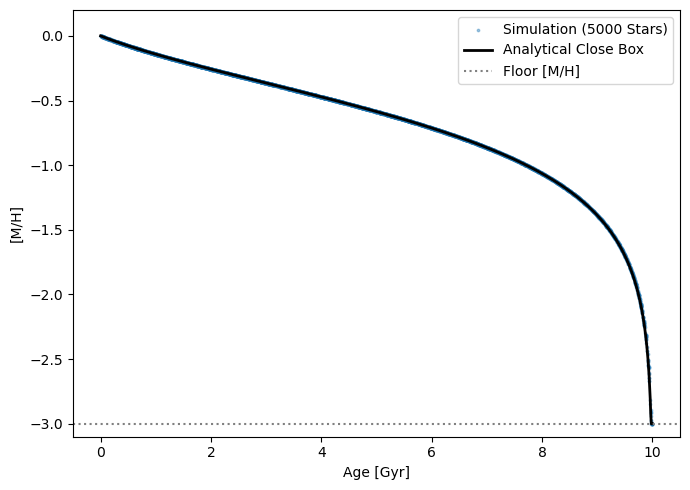

In [16]:
# Submuestra para que el scatter sea legible (las estrellas ya están en orden aleatorio)
n_show = 5000
idx = np.arange(n_show)

# Curva analítica
t_grid = np.linspace(1e-4, T_MW, 1000)          # t_birth
MH_teo = Z_to_MH(closed_box(t_grid))

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(t_age[idx], MH[idx], s=3, alpha=0.4, label=f"Simulation ({n_show} Stars)")
ax.plot(T_MW - t_grid, MH_teo, "k-", lw=2, label="Analytical Close Box")
ax.axhline(MH_FLOOR, ls=":", c="gray", label="Floor [M/H]")
ax.set_xlabel("Age [Gyr]")
ax.set_ylabel("[M/H]")
ax.set_ylim(MH_FLOOR - 0.1, 0.2)
ax.legend()
fig.tight_layout()
plt.savefig("figs/Age-Metallicity Closed Box")
plt.show()

In [17]:
vizier_hay = Vizier(
    columns=["HIP", "[Fe/H]", "ST"],
    row_limit=-1
) 
vizier_gcs = Vizier(
    columns=["HIP", "[Fe/H]"],
    row_limit=-1
)

hay = vizier_hay.get_catalogs("J/MNRAS/325/1365/table3")[0]
gcs = vizier_gcs.get_catalogs("V/130/gcs3")[0]

print(len(hay), len(gcs))

348 16682


In [18]:
seleccion = np.array(hay["ST"].filled(""), dtype=str) == "*"

hay_long = hay[seleccion]

feh_hay = np.array(hay_long["[Fe/H]"].filled(np.nan), dtype=float)
feh_hay = feh_hay[np.isfinite(feh_hay)]


feh_gcs = np.array(gcs["[Fe/H]"].filled(np.nan), dtype=float)
feh_gcs = feh_gcs[np.isfinite(feh_gcs)]

print("Fe/H válidos:", len(feh_hay))
print("Fe/H válidos:", len(feh_gcs))


Fe/H válidos: 218
Fe/H válidos: 16394


## Haywood tiene pocas estrellas mientras que GCS inlcuye estrellas tipo F

## Normalización de la MDF
$$ MDF_i = \frac{N_{i}}{N_{tot}\Delta[\text{Fe}/\text{H}]}$$


Ni corresponde al número de estrellas del intervalo 
Ntot número de estrellas de la muestra
delta[Fe/H] es el ancho del intervalo 

In [19]:
def mdf(values, bins):
    """Calcula la MDF normalizada, su error de Poisson y el tamaño de la muestra."""
    values = np.asarray(values)
    counts, _ = np.histogram(values, bins=bins)
    n_tot = len(values)
    width = np.diff(bins)

    pdf = counts / (n_tot * width)
    error = np.sqrt(counts) / (n_tot * width)

    return pdf, error, n_tot


def frac_below(values, cut):
    """Calcula la fracción de valores inferiores al umbral."""
    values = np.asarray(values)
    return np.mean(values < cut)


def binomial_error(values, cut):
    """Calcula el error binomial de la fracción por debajo del umbral."""
    f = frac_below(values, cut)
    return np.sqrt(f * (1 - f) / len(values))

In [20]:
is_G = is_MS & (M > 0.8) & (M < 1.05)
MH_G = MH[is_G]
n_G = is_G.sum()

print(n_G)

24003


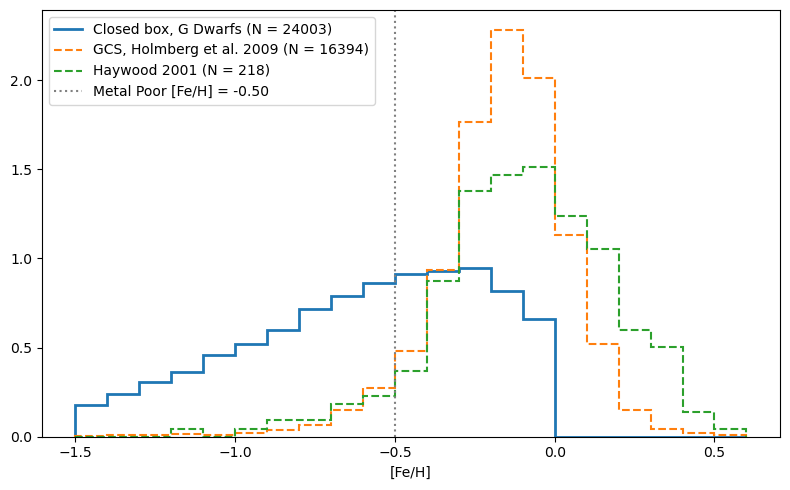

In [21]:
DBIN = 0.1
bins_feh = np.arange(-1.5, 0.6 + DBIN / 2, DBIN)
centers = 0.5 * (bins_feh[1:] + bins_feh[:-1])
MH_G = MH[is_G]                                   

pdf_mod, err_mod, n_mod = mdf(MH_G, bins_feh)
pdf_hay, err_hay, n_hay = mdf(feh_hay, bins_feh)
pdf_gcs, err_gcs, n_gcs = mdf(feh_gcs, bins_feh)

fig, ax = plt.subplots(figsize=(8, 5))
ax.stairs(pdf_mod, bins_feh, lw=2, label=f"Closed box, G Dwarfs (N = {n_mod})")
ax.stairs(pdf_gcs, bins_feh, lw=1.5, ls="--", label=f"GCS, Holmberg et al. 2009 (N = {n_gcs})")
ax.stairs(pdf_hay, bins_feh, lw=1.5,ls="--", label=f"Haywood 2001 (N = {n_hay})")

ax.axvline(-0.5, ls=":", c="gray", label= "Metal Poor [Fe/H] = -0.50")
ax.set_xlabel("[Fe/H]")
ax.legend()
fig.tight_layout()
fig.savefig("figs/mdf_closedbox_vs_obs.png")
plt.show()

In [22]:
# Estadísticas resumidas
print(f"{'Muestra':<10}{'N':>7}   {'f([Fe/H] < -0.5)':<20}{'Pico':>6}")

for nombre, vals, pdf in [
("Modelo", MH_G, pdf_mod),
    ("Haywood", feh_hay, pdf_hay),
    ("GCS", feh_gcs, pdf_gcs)
]:
    f = frac_below(vals, -0.5)
    ef = binomial_error(vals, -0.5)
    max_metal = centers[np.argmax(pdf)]

    print(f"{nombre:<10}{len(vals):>7}   {f:.3f} ± {ef:.3f}     {max_metal:>6.2f}")

# Intervalo con la mayor discrepancia respecto a Haywood
diff = pdf_mod - pdf_hay
i = np.argmax(np.abs(diff))

print(
    f"Mayor discrepancia con Haywood en [Fe/H] = {centers[i]:.2f} "
    f"(modelo - obs = {diff[i]:+.2f})"
)

Muestra         N   f([Fe/H] < -0.5)      Pico
Modelo      24003   0.573 ± 0.003      -0.25
Haywood       218   0.069 ± 0.017      -0.05
GCS         16394   0.060 ± 0.002      -0.15
Mayor discrepancia con Haywood en [Fe/H] = 0.05 (modelo - obs = -1.24)


# **MODELO INFALL**

Un modelo con *infall* se diferencia de un modelo *closed box* en que la galaxia recibe gas desde el medio circundante. En este caso, asumimos que la tasa de acreción disminuye exponencialmente con el tiempo.

Además, suponemos que el gas que ingresa tiene una metalicidad primordial, es decir, $Z_{\rm in}=0$.



## 1. Tasa de acreción de gas

La tasa de acreción se describe mediante una función exponencial:

$$
A(t)=A_0 e^{-t/\tau},
$$

donde \(A_0\) es la tasa inicial de acreción y \(\tau\) es la escala temporal que determina qué tan rápido disminuye el infall.

Para normalizar la masa total del sistema a la unidad al final de la evolución, imponemos la condición:

$$
M_{\rm gas,0}+\int_0^{T_{\rm MW}} A(t)\,dt=1.
$$

Integrando la expresión de \(A(t)\), obtenemos:

$$
A_0=
\frac{1-M_{\rm gas,0}}
{\tau\left(1-e^{-T_{\rm MW}/\tau}\right)}.
$$

De esta manera, la masa inicial de gas más la masa total incorporada mediante el infall es igual a uno.

## 2. Evolución de la masa de gas

La masa de gas evoluciona debido a dos procesos: la acreción de gas y la formación estelar. Su evolución está descrita por:

$$
\frac{dM_{\rm gas}}{dt}=A(t)-\psi(t),
$$

donde \(\psi(t)\) es la tasa de formación estelar.

Suponemos una ley de formación estelar lineal:

$$
\psi(t)=\nu M_{\rm gas}(t),
$$

donde \(\nu\) representa la eficiencia de formación estelar, expresada en \(\mathrm{Gyr}^{-1}\).

Por lo tanto:

$$
\frac{dM_{\rm gas}}{dt}
=A_0e^{-t/\tau}-\nu M_{\rm gas}.
$$

## 3. Evolución química del gas

La evolución de la masa de metales presentes en el gas está determinada por la producción de nuevos metales, la formación estelar y la composición química del gas que ingresa:

$$
\frac{dM_Z}{dt}
=y_{\rm eff}\psi(t)-Z(t)\psi(t)+Z_{\rm in}A(t),
$$

donde:

- \(M_Z\) es la masa de metales presentes en el gas.
- \(y_{\rm eff}\) es el rendimiento efectivo de metales.
- \(Z(t)=M_Z(t)/M_{\rm gas}(t)\) es la metalicidad del gas.
- \(Z_{\rm in}\) es la metalicidad del gas que ingresa.

Como asumimos que el gas entrante no contiene metales, \(Z_{\rm in}=0\), la ecuación se simplifica a:

$$
\frac{dM_Z}{dt}
=y_{\rm eff}\psi(t)-Z(t)\psi(t).
$$

El primer término representa la producción de nuevos metales por las estrellas, mientras que el segundo representa los metales que abandonan la fase gaseosa cuando el gas se transforma en estrellas.

## 4. Evolución de la masa estelar

La masa estelar acumulada evoluciona según:

$$
\frac{dM_\star}{dt}=\psi(t).
$$

En este modelo no incluimos explícitamente el retorno de masa desde las estrellas hacia el medio interestelar.

La masa total del sistema se define como:

$$
M_{\rm tot}(t)=M_{\rm gas}(t)+M_\star(t),
$$

y la fracción de gas como:

$$
\mu(t)=\frac{M_{\rm gas}(t)}
{M_{\rm gas}(t)+M_\star(t)}.
$$

## 5. Calibración del modelo

Para comparar el modelo con infall con el modelo *closed box*, ajustamos los parámetros para reproducir las mismas condiciones finales.

Primero, determinamos la eficiencia de formación estelar \(\nu\) de modo que la fracción de gas final coincida con la del modelo de referencia:

$$
\mu(T_{\rm MW})=\mu_{\rm F}.
$$

Para ello, utilizamos el método numérico `brentq`, que encuentra la raíz de la función:

$$
f(\nu)=\mu(T_{\rm MW};\nu)-\mu_{\rm F}.
$$

Una vez determinada \(\nu\), ajustamos el rendimiento efectivo \(y_{\rm eff}\) para que la metalicidad final del gas sea igual a la metalicidad solar:

$$
Z(T_{\rm MW})=Z_\odot.
$$

Como suponemos que la metalicidad inicial y la metalicidad del gas entrante son nulas, la metalicidad final es proporcional a \(y_{\rm eff}\). Por ello, podemos calcularlo mediante:

$$
y_{\rm eff}=\frac{Z_\odot}{Z(T_{\rm MW})\big|_{y_{\rm eff}=1}}.
$$

Así, cada valor de \(\tau\) define una historia de acreción distinta, mientras que \(\nu\) y \(y_{\rm eff}\) se calibran para mantener iguales la fracción de gas y la metalicidad finales.

Esto permite estudiar cómo la historia de acreción influye en la evolución temporal de la masa gaseosa, la formación estelar y el enriquecimiento químico de la galaxia.

In [23]:
# Modelo con infall
Z_IN       = 0.0           # metalicidad del gas que cae (prístino)
TAU_INFALL = [2.0, 7.0]    # Gyr, tiempos característicos a comparar
M_GAS0     = 0.0           # gas inicial, en unidades de la masa total final
N_T_GRID   = 5000          # pasos de la grilla temporal

In [24]:
def integrate_infall(tau, nu, Mg0=M_GAS0, y_eff=1.0, n_steps=N_T_GRID):
    """
    Integra con Euler explícito el modelo one-zone con infall exponencial y reciclaje instantáneo:
        dM_g/dt = A(t) - psi(t)
        dM_Z/dt = y psi - Z psi + Z_IN A(t)
        A(t) = A0 exp(-t/tau),   psi = nu M_g
    A0 se fija para que la masa total final sea 1:  Mg0 + ∫ A dt = 1.
    Con Mg0 = 1 se obtiene A0 = 0 (sin infall).
    Entradas: tau [Gyr], nu [1/Gyr], Mg0, y_eff, n_steps
    Salida:   dict con arrays t, A, M_gas, M_star, M_Z, Z, psi, mu y el escalar A0
    """
    t = np.linspace(0.0, T_MW, n_steps + 1)
    dt = t[1] - t[0]
    A0 = (1.0 - Mg0) / (tau * (1.0 - np.exp(-T_MW / tau)))
    A = A0 * np.exp(-t / tau)

    M_gas = np.zeros_like(t)
    M_Z = np.zeros_like(t)
    M_star = np.zeros_like(t)
    M_gas[0] = Mg0

    for i in range(n_steps):
        psi_i = nu * M_gas[i]
        Z_i = M_Z[i] / M_gas[i] if M_gas[i] > 0 else 0.0
        M_gas[i + 1]  = M_gas[i]  + (A[i] - psi_i) * dt
        M_Z[i + 1]    = M_Z[i]    + (y_eff * psi_i - Z_i * psi_i + Z_IN * A[i]) * dt
        M_star[i + 1] = M_star[i] + psi_i * dt

    psi = nu * M_gas
    Z = np.divide(M_Z, M_gas, out=np.zeros_like(M_Z), where=M_gas > 0)
    M_tot = M_gas + M_star
    mu = np.divide(M_gas, M_tot, out=np.ones_like(M_gas), where=M_tot > 0)
    return dict(t=t, A=A, A0=A0, M_gas=M_gas, M_star=M_star, M_Z=M_Z, Z=Z, psi=psi, mu=mu)



def build_infall_model(tau, Mg0=M_GAS0):
    """
    Construye el modelo con infall calibrado igual que el closed box:
      - nu tal que mu(T_MW) = MU_F
      - y_eff tal que Z_gas(T_MW) = Z_sun
    """

    # 1) Encontrar nu para reproducir la fracción de gas final
    def mu_final(nu):
        model = integrate_infall(tau, nu, Mg0)
        return model["mu"][-1] - MU_F

    nu = brentq(mu_final, 1e-3, 20.0)

    # 2) Encontrar y_eff para reproducir la metalicidad solar
    model = integrate_infall(tau, nu, Mg0, y_eff=1.0)

    y_eff = Z_sun / model["Z"][-1]

    model["Z"] *= y_eff
    model["M_Z"] *= y_eff

    # 3) Guardar los parámetros
    model.update(nu=nu, y_eff=y_eff, tau=tau)

    return model

In [25]:
def check_model(name, m):
    """Imprime la calibración (mu_f, Z_f) y la conservación de masa de un modelo."""
    M_final = m["M_gas"][-1] + m["M_star"][-1]
    print(f"{name:<22} nu = {m['nu']:.3f} 1/Gyr   y = {m['y_eff']:.5f}   "
          f"mu_f = {m['mu'][-1]:.3f}   Z_f/Z_sun = {m['Z'][-1] / Z_sun:.3f}   "
          f"M_final = {M_final:.4f} (esperado 1)")

models = {tau: build_infall_model(tau) for tau in TAU_INFALL}
test_cb = build_infall_model(tau=1.0, Mg0=1.0)      # A0 = 0: test sin infall

for tau, m in models.items():
    check_model(f"Infall tau = {tau} Gyr", m)
check_model("Test: sin infall", test_cb)
print(f"\ny del closed box base: {y_eff:.5f}")

Infall tau = 2.0 Gyr   nu = 0.312 1/Gyr   y = 0.00692   mu_f = 0.100   Z_f/Z_sun = 1.000   M_final = 1.0005 (esperado 1)
Infall tau = 7.0 Gyr   nu = 0.588 1/Gyr   y = 0.01119   mu_f = 0.100   Z_f/Z_sun = 1.000   M_final = 1.0001 (esperado 1)
Test: sin infall       nu = 0.230 1/Gyr   y = 0.00608   mu_f = 0.100   Z_f/Z_sun = 1.000   M_final = 1.0000 (esperado 1)

y del closed box base: 0.00608


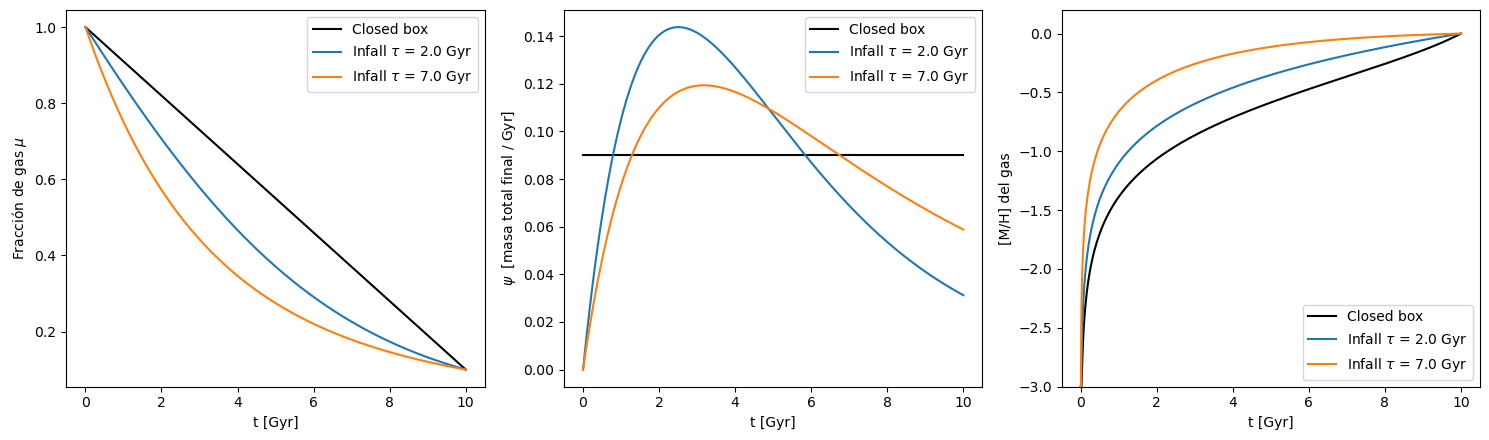

In [26]:
t_cb = np.linspace(0.0, T_MW, 500)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
axes[0].plot(t_cb, gas_fraction(t_cb), "k-", label="Closed box")
axes[1].plot(t_cb, np.full_like(t_cb, (1 - MU_F) / T_MW), "k-", label="Closed box")
axes[2].plot(t_cb, Z_to_MH(closed_box(t_cb)), "k-", label="Closed box")

for tau, m in models.items():
    lab = rf"Infall $\tau$ = {tau} Gyr"
    axes[0].plot(m["t"], m["mu"], label=lab)
    axes[1].plot(m["t"], m["psi"], label=lab)
    axes[2].plot(m["t"], Z_to_MH(m["Z"]), label=lab)

axes[0].set_ylabel(r"Fracción de gas $\mu$")
axes[1].set_ylabel(r"$\psi$  [masa total final / Gyr]")
axes[2].set_ylabel("[M/H] del gas")
axes[2].set_ylim(MH_FLOOR, 0.2)
for ax in axes:
    ax.set_xlabel("t [Gyr]")
    ax.legend()
fig.tight_layout()
fig.savefig("figs/infall_evolution.png")
plt.show()